# FP32 DRAM roofline from five binary Nsight Compute reports

This notebook uses NVIDIA's **`ncu_report`** API (`pip install ncu-report`) to read five `.ncu-rep` files: constant memory without a register cap, then caps of 96, 85, **80** and 75. All configurations render the same scene at 640 × 360, with 64 threads/block and 16 threads/pixel.

The **80-register configuration** is the winner. Per the experimenter's clarification, **29.589 ms** was measured during the profiling session, and **29.059 ms** is the separate standalone run of the same configuration. The binary report additionally records a **34.624160 ms Nsight kernel duration**. These are different timing observations: the roofline uses the binary report's duration with its counters. The standalone timing identifies the winning configuration and is shown alongside it.



## Setup

The next cell installs NVIDIA's standalone report reader if necessary. Reading these existing reports does **not** require a live NVIDIA GPU, CUDA profiling permissions, or collecting new profiles.



In [1]:
import importlib.util
if importlib.util.find_spec("ncu_report") is None:
    get_ipython().run_line_magic("pip", "install -q ncu-report==2026.3.1 numpy matplotlib")
import ncu_report
from importlib.metadata import version
print("ncu-report version:", version("ncu-report"))

ncu-report version: 2026.3.1


In [ ]:
from pathlib import Path
from io import BytesIO
import sys
from IPython.display import display, Markdown, Image
import matplotlib.pyplot as plt
plt.switch_backend("Agg")

PROJECT_ROOT = Path.cwd()  
ROOT = next((p for p in (PROJECT_ROOT, *PROJECT_ROOT.parents)
             if (p / "roofline_analysis.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Set PROJECT_ROOT to the folder containing roofline_analysis.py and stats/")
sys.path.insert(0, str(ROOT))
from roofline_analysis import load_profiles, plot_roofline, write_outputs
rows, peak_gbps = load_profiles(ROOT)
best = min(rows, key=lambda r: r["standalone_ms"])
print(f"Read {len(rows)} binary profiles; winner: {best['label']}")
print(f"Winner: profiling-session timing {best['benchmark_ms']:.3f} ms; "
      f"standalone {best['standalone_ms']:.3f} ms; Nsight kernel {best['profile_ms']:.6f} ms")

Read 5 binary profiles; winner: 80-register cap
Winner: profiling-session timing 29.589 ms; standalone 29.059 ms; Nsight kernel 34.624160 ms


## Calculations and counter definitions



In [3]:
lines = ["| Profile | Nsight kernel ms | Saved benchmark ms | Standalone ms | TFLOP/s | DRAM GB/s | GFLOP/frame | DRAM MB/frame | FLOP/byte | Occupancy % |",
         "|" + "---|" * 10]
for i, r in enumerate(rows, 1):
    label = f"{i}. {r['label']}" + (" **(winner)**" if r is best else "")
    lines.append(f"| {label} | {r['profile_ms']:.6f} | {r['benchmark_ms']:.3f} | {r['standalone_ms']:.3f} | "
                 f"{r['achieved_tflops']:.4f} | {r['dram_gbps']:.4f} | {r['work_gflop']:.3f} | "
                 f"{r['traffic_mb']:.3f} | {r['intensity']:.2f} | {r['occupancy_pct']:.2f} |")
display(Markdown("\n".join(lines)))
display(Markdown("**Timing note:** the saved 29.589 ms benchmark for the 80-register configuration "
                 "was taken during the profiling session (experimenter clarification). Its separate "
                 "standalone result is 29.059 ms. Other standalone columns reproduce the saved benchmark files."))

| Profile | Nsight kernel ms | Saved benchmark ms | Standalone ms | TFLOP/s | DRAM GB/s | GFLOP/frame | DRAM MB/frame | FLOP/byte | Occupancy % |
|---|---|---|---|---|---|---|---|---|---|
| 1. Constant memory (uncapped) | 43.912608 | 33.740 | 33.740 | 1.0404 | 0.4519 | 45.686 | 19.845 | 2302.13 | 31.18 |
| 2. 96-register cap | 37.849728 | 31.672 | 31.672 | 1.2070 | 0.5589 | 45.686 | 21.153 | 2159.79 | 39.03 |
| 3. 85-register cap | 37.935328 | 31.662 | 31.662 | 1.2043 | 2.9031 | 45.686 | 110.130 | 414.84 | 39.02 |
| 4. 80-register cap **(winner)** | 34.624160 | 29.589 | 29.059 | 1.3195 | 8.9923 | 45.686 | 311.352 | 146.73 | 46.84 |
| 5. 75-register cap | 35.139200 | 30.037 | 30.037 | 1.3001 | 14.8875 | 45.686 | 523.136 | 87.33 | 46.79 |

**Timing note:** the saved 29.589 ms benchmark for the 80-register configuration was taken during the profiling session (experimenter clarification). Its separate standalone result is 29.059 ms. Other standalone columns reproduce the saved benchmark files.

## Five-point roofline

The five numbered markers match the table; the star marks the 80-register configuration. Each marker uses that binary report's instruction work, DRAM bytes and Nsight duration. Standalone timing is not substituted into these profiling coordinates.

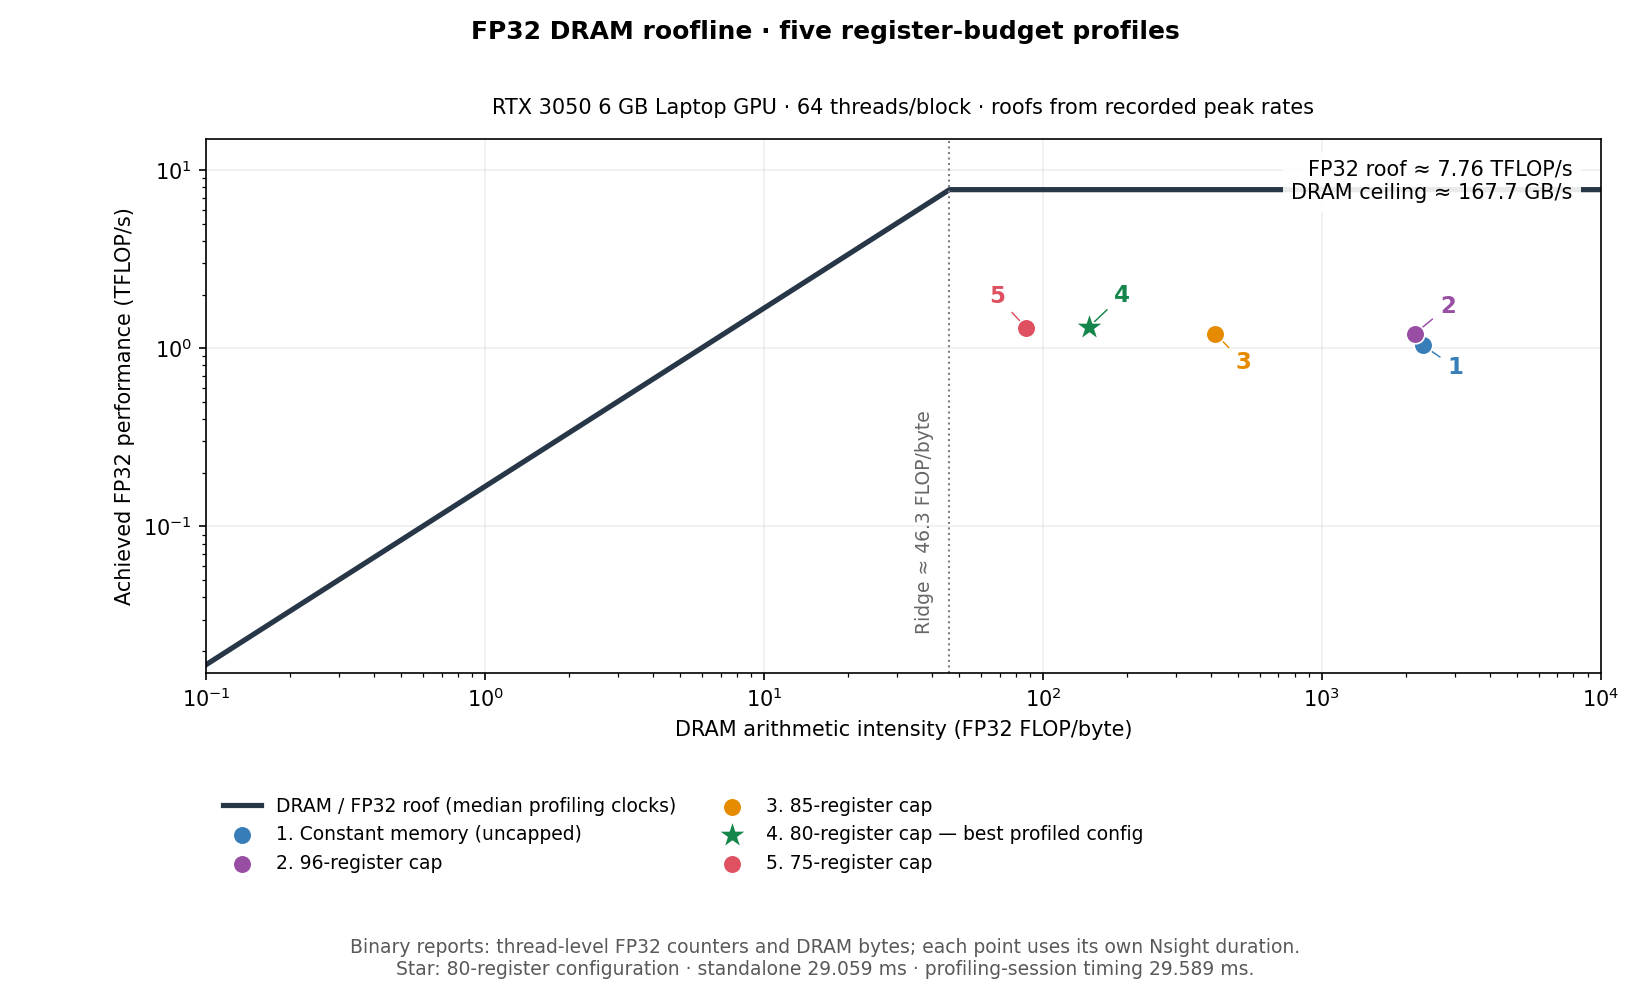

In [4]:
fig = plot_roofline(rows, peak_gbps)
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=150)
plt.close(fig)
display(Image(data=buffer.getvalue()))
write_outputs(rows, peak_gbps, ROOT / "stats/reports")

## Reading the result

All five points lie on the compute side of the simplified DRAM roofline. This means the FP32 ceiling is lower than the DRAM ceiling at their measured intensities; it does not establish that FP32 arithmetic is saturated. Dependencies, divergence, integer/control work, special functions and scheduling can explain the remaining gap.

The 80-register cap improves occupancy and timing compared with 96 and 85. Lowering the cap to 75 leaves occupancy nearly unchanged but increases measured DRAM traffic and worsens time, consistent with the spill tradeoff recorded in the repository.

In [5]:
r = best
ridge = r['fp32_peak_tflops'] * 1000 / r['dram_peak_gbps']
display(Markdown(
    f"**80-register result:** {r['work_gflop']:.3f} GFLOP and {r['traffic_mb']:.3f} MB "
    f"in {r['profile_ms']:.6f} ms give **{r['achieved_tflops']:.4f} TFLOP/s** and "
    f"**{r['intensity']:.2f} FLOP/byte**. Its FP32 roof is {r['fp32_peak_tflops']:.3f} TFLOP/s "
    f"and DRAM roof is {r['dram_peak_gbps']:.3f} GB/s (ridge {ridge:.2f} FLOP/byte). "
    f"It reaches {r['roof_fraction_pct']:.2f}% of its roof."
))
assert len(rows) == 5 and len({r['source'] for r in rows}) == 5
assert best['config'] == '80_registers'
assert abs(best['profile_ms'] - 34.624160) < 1e-6
assert abs(best['benchmark_ms'] - 29.589) < 1e-6
assert abs(best['standalone_ms'] - 29.059) < 1e-6
for r in rows:
    assert r['intensity'] > r['fp32_peak_tflops'] * 1000 / r['dram_peak_gbps']
    assert 0 < r['roof_fraction_pct'] <= 100
    assert abs(r['work_gflop'] / r['profile_ms'] - r['achieved_tflops']) < 1e-10
    for field in ('source', 'timing_source', 'standalone_source'):
        assert (ROOT / r[field]).is_file()
print("Profile selection, timing, units and roofline checks passed.")

**80-register result:** 45.686 GFLOP and 311.352 MB in 34.624160 ms give **1.3195 TFLOP/s** and **146.73 FLOP/byte**. Its FP32 roof is 7.756 TFLOP/s and DRAM roof is 167.688 GB/s (ridge 46.25 FLOP/byte). It reaches 17.01% of its roof.

Profile selection, timing, units and roofline checks passed.


## Inspect a report directly

The example below opens the winning report through NVIDIA's API and prints the exact input metric names, values and units. The generated CSV contains provenance for all five points, including the normalized instruction-counter expressions, hardware, clocks and timing sources.

In [6]:
context = ncu_report.load_report(str(ROOT / best['source']))
action = context.range_by_idx(best['range_index']).action_by_idx(best['action_index'])
print("Kernel:", action.name())
for name in ("gpu__time_duration.avg", "smsp__cycles_elapsed.sum",
             "smsp__sass_thread_inst_executed_op_fadd_pred_on.avg.per_cycle_elapsed",
             "smsp__sass_thread_inst_executed_op_fmul_pred_on.avg.per_cycle_elapsed",
             "smsp__sass_thread_inst_executed_op_ffma_pred_on.avg.per_cycle_elapsed",
             "dram__bytes_read.sum", "dram__bytes_write.sum",
             "sm__sass_thread_inst_executed_op_ffma_pred_on.sum.peak_sustained",
             "sm__cycles_elapsed.avg.per_second", "dram__bytes.sum.peak_sustained",
             "dram__cycles_elapsed.avg.per_second"):
    metric = action.metric_by_name(name)
    print(f"{name}: {metric.value()} {metric.unit()}")

Kernel: render_kernel
gpu__time_duration.avg: 34624160.0 ns
smsp__cycles_elapsed.sum: 4195806880.0 cycle
smsp__sass_thread_inst_executed_op_fadd_pred_on.avg.per_cycle_elapsed: 0.9829318605340578 inst/cycle
smsp__sass_thread_inst_executed_op_fmul_pred_on.avg.per_cycle_elapsed: 1.4045752320230718 inst/cycle
smsp__sass_thread_inst_executed_op_ffma_pred_on.avg.per_cycle_elapsed: 4.250463658375049 inst/cycle
dram__bytes_read.sum: 37671808.0 byte
dram__bytes_write.sum: 273680384.0 byte
sm__sass_thread_inst_executed_op_ffma_pred_on.sum.peak_sustained: 2560.0 inst/cycle
sm__cycles_elapsed.avg.per_second: 1514768473.805574 hz
dram__bytes.sum.peak_sustained: 24.0 byte/cycle
dram__cycles_elapsed.avg.per_second: 6986999135.863512 hz
